# 文埋め込みを 2 次元に可視化する (UMAP)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpcookbook/blob/main/notebooks/11_similarity_search/embedding_umap.ipynb)

NLP クックブック 11-13 ／ 文埋め込み・類似度・検索

文の埋め込みベクトルを散布図にして、データセットの全体像 (クラスの分かれ方、外れ値) を眺めたい。

In [1]:
!pip install -q umap-learn

In [2]:
import numpy as np
from sentence_transformers import SentenceTransformer
from sklearn.datasets import fetch_20newsgroups

cats = ["rec.sport.baseball", "sci.space", "comp.graphics", "talk.politics.mideast", "rec.autos"]
data = fetch_20newsgroups(subset="train", categories=cats, remove=("headers", "footers", "quotes"))
keep = [i for i, d in enumerate(data.data) if len(d) > 100][:1500]
texts, y = [data.data[i][:1000] for i in keep], np.array([data.target[i] for i in keep])

model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
emb = model.encode(texts, batch_size=64, normalize_embeddings=True, show_progress_bar=False)
print(emb.shape)

(1500, 384)


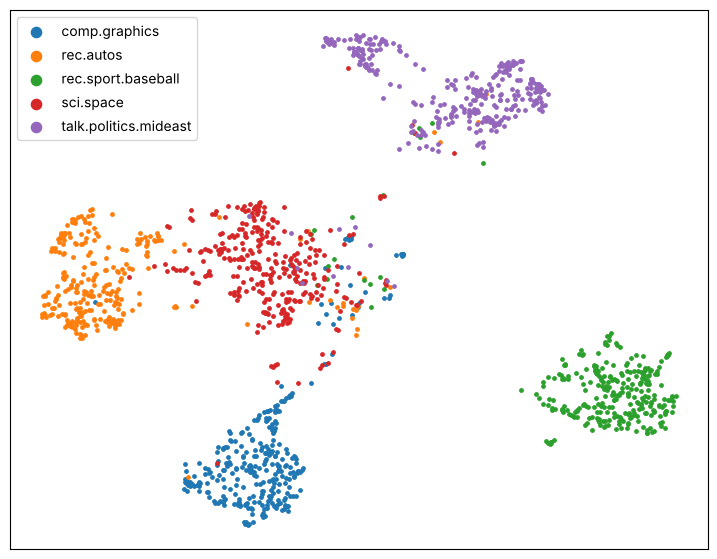

In [3]:
import matplotlib.pyplot as plt
import umap

Z = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine", random_state=0).fit_transform(emb)
plt.figure(figsize=(9, 7))
for c, name in enumerate(data.target_names):
    plt.scatter(Z[y == c, 0], Z[y == c, 1], s=6, label=name)
plt.legend(markerscale=3); plt.xticks([]); plt.yticks([]); plt.show()

- UMAP は t-SNE より速く、大域的な配置も比較的保たれる。`n_neighbors` を大きくすると大域構造、小さくすると局所構造を重視する。
- 点にマウスを載せて原文を見たいなら Plotly: `px.scatter(x=Z[:,0], y=Z[:,1], color=..., hover_name=texts)`。